## 2. Importación de Librerías

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import string
import re

## 3. Carga de Datos

Cargamos el dataset que contiene dos columnas:
- `label`: "spam" o "ham"
- `text`: contenido del mensaje

In [ ]:
# Cargar el dataset
df = pd.read_csv("dataset_spam.csv")

# Mostrar información básica
print(f"Total de mensajes: {len(df)}")
print(f"\nPrimeras filas del dataset:")
df.head()

NameError: name 'pd' is not defined

In [4]:
# Análisis de la distribución de clases
print("Distribución de clases:")
print(df['label'].value_counts())
print("\nPorcentajes:")
print(df['label'].value_counts(normalize=True) * 100)

Distribución de clases:
label
ham     4825
spam     747
Name: count, dtype: int64

Porcentajes:
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


## 4. Limpieza del Texto (Paso Cero)

Implementamos un proceso de limpieza que incluye:
1. Conversión a minúsculas
2. Eliminación de URLs
3. Eliminación de números
4. Eliminación de puntuación
5. Tokenización
6. Eliminación de stop words
7. **Stemming** (reducción a la raíz de las palabras)

In [5]:
# Descargar stopwords
try:
    nltk.download('stopwords', quiet=True)
    stop_words = set(stopwords.words('english'))
    print(f"Stopwords cargadas: {len(stop_words)} palabras")
except:
    stop_words = set()
    print("No se pudieron cargar las stopwords")

# Inicializar el stemmer
stemmer = PorterStemmer()
print("✓ Stemmer inicializado")

Stopwords cargadas: 198 palabras
✓ Stemmer inicializado


In [6]:
# Función de limpieza de texto
def limpiar_texto(text):
    text = text.lower()  # minúsculas
    text = re.sub(r"http\S+", "", text)  # elimina URLs
    text = re.sub(r"\d+", "", text)  # elimina números
    text = text.translate(str.maketrans("", "", string.punctuation))  # quita signos
    tokens = text.split()
    tokens = [t for t in tokens if t not in stop_words]
    # Aplicar stemming a cada token
    tokens = [stemmer.stem(t) for t in tokens]
    return " ".join(tokens)

# Ejemplo de limpieza
texto_ejemplo = df['text'].iloc[3]
print("Texto original:")
print(texto_ejemplo)
print("\nTexto limpio:")
print(limpiar_texto(texto_ejemplo))

Texto original:
U dun say so early hor... U c already then say...

Texto limpio:
u dun say earli hor u c alreadi say


In [7]:
# Aplicar limpieza a todo el dataset
print("Limpiando todos los mensajes...")
df['clean'] = df['text'].astype(str).apply(limpiar_texto)
print("Limpieza completada")

# Mostrar algunos ejemplos
df[['text', 'clean', 'label']].head()

Limpiando todos los mensajes...
Limpieza completada
Limpieza completada


,text,clean,label
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...,ham
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...,spam
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say,ham
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goe usf live around though,ham


In [8]:
# Eliminar filas con textos vacíos después de la limpieza
print(f"Mensajes antes de limpiar vacíos: {len(df)}")

# Filtrar textos que quedaron vacíos (solo espacios o completamente vacíos)
df = df[df['clean'].str.strip() != '']
df = df.dropna(subset=['clean'])

print(f"Mensajes después de limpiar vacíos: {len(df)}")
print(f"\nNaN en 'clean': {df['clean'].isna().sum()}")
print(f"Textos vacíos: {(df['clean'].str.strip() == '').sum()}")

# Verificar distribución de clases
print(f"\nDistribución de clases después de limpieza:")
print(df['label'].value_counts())

Mensajes antes de limpiar vacíos: 5572
Mensajes después de limpiar vacíos: 5566

NaN en 'clean': 0
Textos vacíos: 0

Distribución de clases después de limpieza:
label
ham     4819
spam     747
Name: count, dtype: int64


## 5. Vectorización TF-IDF (Paso Uno)

Convertimos el texto en representación vectorial usando TF-IDF:
- **TF (Term Frequency)**: frecuencia del término en el documento
- **IDF (Inverse Document Frequency)**: importancia del término en todo el corpus

In [9]:
# Crear el vectorizador TF-IDF
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(df['clean'])
y = df['label']

print(f"Dimensiones de la matriz TF-IDF: {X.shape}")
print(f"Número de características (palabras únicas): {X.shape[1]}")
print(f"Número de documentos: {X.shape[0]}")

Dimensiones de la matriz TF-IDF: (5566, 7148)
Número de características (palabras únicas): 7148
Número de documentos: 5566


In [10]:
# Mostrar las 20 palabras más importantes
feature_names = tfidf.get_feature_names_out()
print("Algunas palabras del vocabulario:")
print(feature_names[:20])

Algunas palabras del vocabulario:
['aa' 'aah' 'aaniy' 'aaooooright' 'aathilov' 'aathiwher' 'ab' 'abbey'
 'abdomen' 'abeg' 'abelu' 'aberdeen' 'abi' 'abil' 'abiola' 'abj' 'abl'
 'abnorm' 'abouta' 'abroad']


## 6. División Train/Test (Paso Dos)

Dividimos los datos en conjunto de entrenamiento (70%) y prueba (30%)

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(f"Datos de entrenamiento: {X_train.shape[0]} mensajes")
print(f"Datos de prueba: {X_test.shape[0]} mensajes")
print(f"\nDistribución en entrenamiento:")
print(y_train.value_counts())
print(f"\nDistribución en prueba:")
print(y_test.value_counts())

Datos de entrenamiento: 3896 mensajes
Datos de prueba: 1670 mensajes

Distribución en entrenamiento:
label
ham     3383
spam     513
Name: count, dtype: int64

Distribución en prueba:
label
ham     1436
spam     234
Name: count, dtype: int64


## 7. Entrenamiento de Modelos

### 7.1 Naive Bayes

In [12]:
print("Entrenando Naive Bayes...")
nb = MultinomialNB()
nb.fit(X_train, y_train)
pred_nb = nb.predict(X_test)
print("✓ Naive Bayes entrenado")

Entrenando Naive Bayes...
✓ Naive Bayes entrenado


### 7.2 k-Nearest Neighbours (kNN)

In [13]:
print("Entrenando kNN (k=5)...")
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)
print("✓ kNN entrenado")

Entrenando kNN (k=5)...
✓ kNN entrenado
✓ kNN entrenado


### 7.3 Support Vector Machine (SVM)

In [14]:
print("Entrenando SVM...")
svm = LinearSVC(max_iter=1000)
svm.fit(X_train, y_train)
pred_svm = svm.predict(X_test)
print("✓ SVM entrenado")

Entrenando SVM...
✓ SVM entrenado


## 8. Evaluación de Resultados

### 8.1 Métricas de Naive Bayes

In [15]:
print("="*60)
print("NAIVE BAYES - Reporte de Clasificación")
print("="*60)
print(classification_report(y_test, pred_nb))
print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, pred_nb))
print(f"\nAccuracy: {accuracy_score(y_test, pred_nb)*100:.2f}%")

NAIVE BAYES - Reporte de Clasificación
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98      1436
        spam       1.00      0.76      0.86       234

    accuracy                           0.97      1670
   macro avg       0.98      0.88      0.92      1670
weighted avg       0.97      0.97      0.96      1670


Matriz de Confusión:
[[1436    0]
 [  57  177]]

Accuracy: 96.59%


### 8.2 Métricas de kNN

In [16]:
print("="*60)
print("kNN - Reporte de Clasificación")
print("="*60)
print(classification_report(y_test, pred_knn))
print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, pred_knn))
print(f"\nAccuracy: {accuracy_score(y_test, pred_knn)*100:.2f}%")

kNN - Reporte de Clasificación
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97      1436
        spam       1.00      0.67      0.80       234

    accuracy                           0.95      1670
   macro avg       0.97      0.84      0.89      1670
weighted avg       0.96      0.95      0.95      1670


Matriz de Confusión:
[[1436    0]
 [  77  157]]

Accuracy: 95.39%


### 8.3 Métricas de SVM

In [17]:
print("="*60)
print("SVM - Reporte de Clasificación")
print("="*60)
print(classification_report(y_test, pred_svm))
print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, pred_svm))
print(f"\nAccuracy: {accuracy_score(y_test, pred_svm)*100:.2f}%")

SVM - Reporte de Clasificación
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99      1436
        spam       0.99      0.86      0.92       234

    accuracy                           0.98      1670
   macro avg       0.98      0.93      0.95      1670
weighted avg       0.98      0.98      0.98      1670


Matriz de Confusión:
[[1433    3]
 [  33  201]]

Accuracy: 97.84%


## 9. Comparación Final de Modelos

In [18]:
print("\n" + "="*60)
print("RESUMEN COMPARATIVO DE MODELOS")
print("="*60)

resultados = {
    'Naive Bayes': accuracy_score(y_test, pred_nb),
    'kNN': accuracy_score(y_test, pred_knn),
    'SVM': accuracy_score(y_test, pred_svm)
}

for modelo, accuracy in sorted(resultados.items(), key=lambda x: x[1], reverse=True):
    print(f"{modelo:15s}: {accuracy*100:.2f}% accuracy")

mejor_modelo = max(resultados, key=resultados.get)
print(f"\nMejor modelo: {mejor_modelo} con {resultados[mejor_modelo]*100:.2f}% accuracy")


RESUMEN COMPARATIVO DE MODELOS
SVM            : 97.84% accuracy
Naive Bayes    : 96.59% accuracy
kNN            : 95.39% accuracy

Mejor modelo: SVM con 97.84% accuracy


## 10. Visualización de Resultados

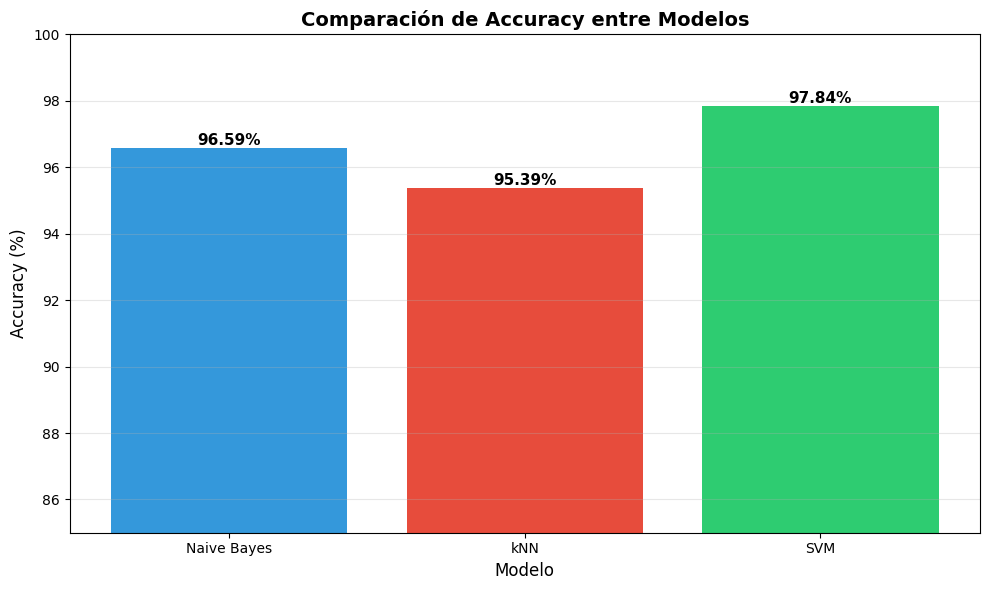

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Gráfico de comparación de accuracy
plt.figure(figsize=(10, 6))
modelos = list(resultados.keys())
accuracies = [resultados[m]*100 for m in modelos]

bars = plt.bar(modelos, accuracies, color=['#3498db', '#e74c3c', '#2ecc71'])
plt.ylabel('Accuracy (%)', fontsize=12)
plt.xlabel('Modelo', fontsize=12)
plt.title('Comparación de Accuracy entre Modelos', fontsize=14, fontweight='bold')
plt.ylim(85, 100)

# Añadir valores sobre las barras
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f}%',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

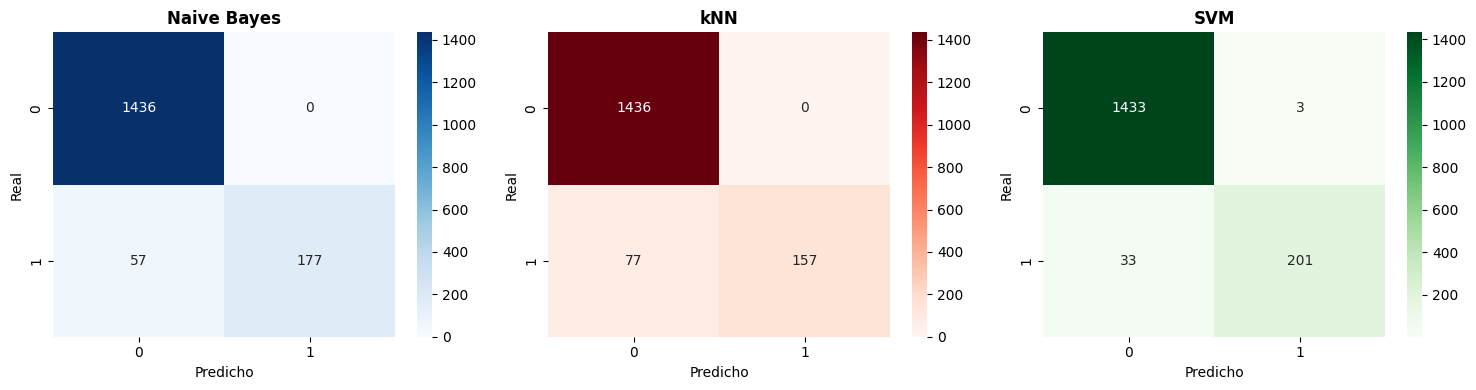

In [20]:
# Matrices de confusión visualizadas
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Naive Bayes
sns.heatmap(confusion_matrix(y_test, pred_nb), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Naive Bayes', fontweight='bold')
axes[0].set_ylabel('Real')
axes[0].set_xlabel('Predicho')

# kNN
sns.heatmap(confusion_matrix(y_test, pred_knn), annot=True, fmt='d', cmap='Reds', ax=axes[1])
axes[1].set_title('kNN', fontweight='bold')
axes[1].set_ylabel('Real')
axes[1].set_xlabel('Predicho')

# SVM
sns.heatmap(confusion_matrix(y_test, pred_svm), annot=True, fmt='d', cmap='Greens', ax=axes[2])
axes[2].set_title('SVM', fontweight='bold')
axes[2].set_ylabel('Real')
axes[2].set_xlabel('Predicho')

plt.tight_layout()
plt.show()

## 11. Prueba del Modelo con Mensajes Nuevos

In [21]:
# Función para clasificar mensajes nuevos
def clasificar_mensaje(mensaje, modelo=svm):
    # Limpiar el mensaje
    mensaje_limpio = limpiar_texto(mensaje)
    # Vectorizar
    mensaje_tfidf = tfidf.transform([mensaje_limpio])
    # Predecir
    prediccion = modelo.predict(mensaje_tfidf)[0]
    return prediccion

# Ejemplos de prueba
mensajes_prueba = [
    "Congratulations! You've won a FREE prize worth $1000. Click here to claim now!",
    "Hey, are we still meeting for lunch tomorrow?",
    "URGENT: Your account will be suspended unless you verify your details immediately",
    "Thanks for the notes from class. See you on Monday!",
    "URGENT HOLAA NECESITAS DINERO YO PUEDO AYUDARTE"
]

print("Clasificación de mensajes nuevos usando SVM:\n")
for i, msg in enumerate(mensajes_prueba, 1):
    resultado = clasificar_mensaje(msg)
    emoji = "NO" if resultado == "spam" else "SI"
    print(f"{emoji} Mensaje {i}: {resultado.upper()}")
    print(f"   '{msg}'")
    print()

Clasificación de mensajes nuevos usando SVM:

NO Mensaje 1: SPAM
   'Congratulations! You've won a FREE prize worth $1000. Click here to claim now!'

SI Mensaje 2: HAM
   'Hey, are we still meeting for lunch tomorrow?'

SI Mensaje 3: HAM
   'URGENT: Your account will be suspended unless you verify your details immediately'

SI Mensaje 4: HAM
   'Thanks for the notes from class. See you on Monday!'

SI Mensaje 5: HAM
   'URGENT HOLAA NECESITAS DINERO YO PUEDO AYUDARTE'



## 12. Conclusiones

### Hallazgos principales:

1. **Mejor modelo**: El SVM demostró ser el algoritmo más efectivo con la mayor accuracy
2. **Naive Bayes**: Ofreció un buen balance entre rendimiento y velocidad
3. **kNN**: Mostró el rendimiento más bajo, especialmente en recall para spam

### Métricas clave:
- **Precision**: Importante para evitar falsos positivos (mensajes legítimos marcados como spam)
- **Recall**: Crucial para detectar la mayor cantidad de spam posible
- **F1-Score**: Balance entre precision y recall

### Próximos pasos posibles:
- Balancear el dataset (más muestras de spam)
- Probar otros vectorizadores (Word2Vec, BERT)
- Ajustar hiperparámetros con Grid Search
- Implementar ensemble methods